In [1]:
import sys

print(sys.executable)

D:\CKD-FastAPI\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import json
import os

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
df = pd.read_csv("../data/kidney_disease.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (400, 25)


In [6]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,normal,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,normal,normal,notpresent,notpresent,121.0,...,38,6000,5.2,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,5.2,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [7]:
df.tail()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,140.0,...,47,6700,4.9,no,no,no,good,no,no,notckd
396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,75.0,...,54,7800,6.2,no,no,no,good,no,no,notckd
397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,100.0,...,49,6600,5.4,no,no,no,good,no,no,notckd
398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,114.0,...,51,7200,5.9,no,no,no,good,no,no,notckd
399,58.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,131.0,...,53,6800,6.1,no,no,no,good,no,no,notckd


In [9]:
print("Columns:")
for column in df.columns:
    print(column)

Columns:
age
bp
sg
al
su
rbc
pc
pcc
ba
bgr
bu
sc
sod
pot
hemo
pcv
wc
rc
htn
dm
cad
appet
pe
ane
classification


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             400 non-null    float64
 1   bp              400 non-null    float64
 2   sg              400 non-null    float64
 3   al              400 non-null    float64
 4   su              400 non-null    float64
 5   rbc             400 non-null    str    
 6   pc              400 non-null    str    
 7   pcc             400 non-null    str    
 8   ba              400 non-null    str    
 9   bgr             400 non-null    float64
 10  bu              400 non-null    float64
 11  sc              400 non-null    float64
 12  sod             400 non-null    float64
 13  pot             400 non-null    float64
 14  hemo            400 non-null    float64
 15  pcv             400 non-null    str    
 16  wc              400 non-null    str    
 17  rc              400 non-null    str    
 18  h

In [12]:
df.isnull().sum()

age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64

In [13]:
print("Question-mark values:")
print((df == "?").sum())

Question-mark values:
age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64


In [14]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


In [15]:
df = df.replace("?", np.nan)

print("Missing values after replacement:")
print(df.isnull().sum())

Missing values after replacement:
age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64


In [16]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [17]:
print(df["classification"].value_counts(dropna=False))

classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


In [18]:
df["classification"] = (
    df["classification"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df["classification"].value_counts())

classification
ckd       250
notckd    150
Name: count, dtype: int64


In [19]:
df["target"] = df["classification"].map({
    "ckd": 1,
    "notckd": 0
})

print(df["target"].value_counts())

target
1    250
0    150
Name: count, dtype: int64


In [20]:
print("Missing target values:", df["target"].isnull().sum())

Missing target values: 0


In [21]:
df = df.drop(columns=["id", "classification"], errors="ignore")

print(df.columns.tolist())

['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'target']


In [22]:
X = df.drop(columns=["target"])
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (400, 24)
Target shape: (400,)


In [23]:
print("Numerical columns:")
print(X.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(exclude=["number"]).columns.tolist())

Numerical columns:
['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo']

Categorical columns:
['rbc', 'pc', 'pcc', 'ba', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [25]:
numerical_features = [
    col for col in numerical_features
    if col in X.columns
]

print("Numerical features:")
print(numerical_features)

Numerical features:
['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']


In [26]:
for col in numerical_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

In [27]:
categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Categorical features:")
print(categorical_features)

Categorical features:
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [28]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     400 non-null    float64
 1   bp      400 non-null    float64
 2   sg      400 non-null    float64
 3   al      400 non-null    float64
 4   su      400 non-null    float64
 5   rbc     400 non-null    str    
 6   pc      400 non-null    str    
 7   pcc     400 non-null    str    
 8   ba      400 non-null    str    
 9   bgr     400 non-null    float64
 10  bu      400 non-null    float64
 11  sc      400 non-null    float64
 12  sod     400 non-null    float64
 13  pot     400 non-null    float64
 14  hemo    400 non-null    float64
 15  pcv     399 non-null    float64
 16  wc      399 non-null    float64
 17  rc      399 non-null    float64
 18  htn     400 non-null    str    
 19  dm      400 non-null    str    
 20  cad     400 non-null    str    
 21  appet   400 non-null    str    
 22  pe      400 n

In [29]:
X.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
count,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,399.000000,399.000000,399.000000
mean,51.562500,76.575000,1.017712,0.90000,0.395000,145.062500,56.693000,2.997125,137.631250,4.577250,12.54250,39.255639,8772.932331,4.867920
std,16.982996,13.489785,0.005434,1.31313,1.040038,75.260774,49.395258,5.628886,9.206332,2.821357,2.71649,8.200981,2600.061687,0.872542
min,2.000000,50.000000,1.005000,0.00000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.10000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.015000,0.00000,0.000000,101.000000,27.000000,0.900000,135.000000,4.000000,10.87500,34.000000,6950.000000,4.500000
50%,55.000000,80.000000,1.020000,0.00000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.65000,41.000000,9400.000000,5.200000
75%,64.000000,80.000000,1.020000,2.00000,0.000000,150.000000,61.750000,2.725000,141.000000,4.800000,14.62500,44.000000,9800.000000,5.200000
max,90.000000,180.000000,1.025000,5.00000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.80000,54.000000,26400.000000,8.000000


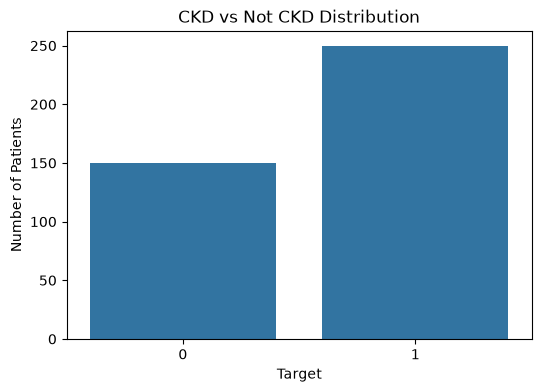

In [30]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("CKD vs Not CKD Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")

plt.show()

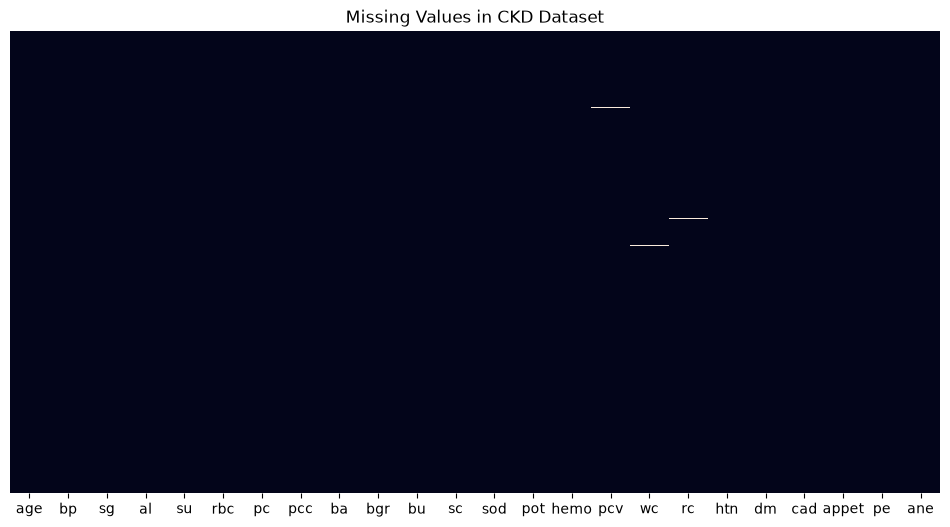

In [31]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    X.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in CKD Dataset")
plt.show()

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 320
Testing samples: 80


In [33]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [35]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [36]:
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ]
)

In [37]:
pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [38]:
y_pred = pipeline.predict(X_test)

print("Predictions generated.")

Predictions generated.


In [40]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


In [41]:
precision = precision_score(y_test, y_pred, zero_division=0)

print("Precision:", precision)

Precision: 1.0


In [42]:
recall = recall_score(y_test, y_pred, zero_division=0)

print("Recall:", recall)

Recall: 1.0


In [43]:
f1 = f1_score(y_test, y_pred, zero_division=0)

print("F1 Score:", f1)

F1 Score: 1.0


In [44]:
print("===== MODEL EVALUATION =====")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

===== MODEL EVALUATION =====
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000


In [45]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not CKD", "CKD"]
))

              precision    recall  f1-score   support

     Not CKD       1.00      1.00      1.00        30
         CKD       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



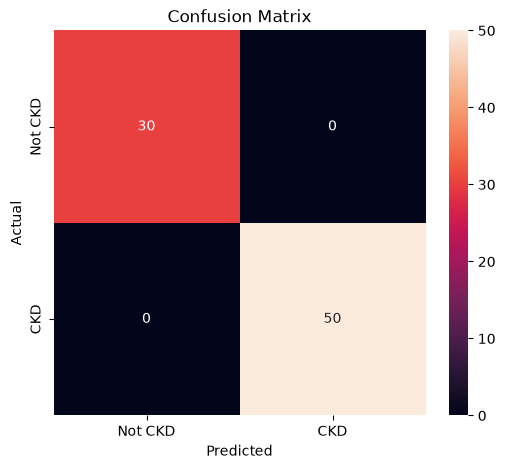

In [46]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not CKD", "CKD"],
    yticklabels=["Not CKD", "CKD"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [47]:
y_probability = pipeline.predict_proba(X_test)

print(y_probability[:5])

[[1.    0.   ]
 [0.025 0.975]
 [0.09  0.91 ]
 [0.985 0.015]
 [0.035 0.965]]


In [48]:
print(pipeline.classes_)

[0 1]


In [49]:
os.makedirs("model", exist_ok=True)

In [50]:
model_path = "model/ckd_pipeline.joblib"

joblib.dump(pipeline, model_path)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
model/ckd_pipeline.joblib


In [51]:
model_info = {
    "model_name": "CKD Prediction Model",
    "version": "1.0.0",
    "algorithm": "Random Forest Classifier",
    "number_of_features": int(X.shape[1]),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("model/model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print(json.dumps(model_info, indent=4))

{
    "model_name": "CKD Prediction Model",
    "version": "1.0.0",
    "algorithm": "Random Forest Classifier",
    "number_of_features": 24,
    "accuracy": 1.0,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0
}


In [52]:
loaded_pipeline = joblib.load(
    "model/ckd_pipeline.joblib"
)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [53]:
test_prediction = loaded_pipeline.predict(X_test.iloc[:5])

print("Predictions:", test_prediction)

Predictions: [0 1 1 0 1]


In [54]:
test_probability = loaded_pipeline.predict_proba(
    X_test.iloc[:5]
)

print(test_probability)

[[1.    0.   ]
 [0.025 0.975]
 [0.09  0.91 ]
 [0.985 0.015]
 [0.035 0.965]]


In [55]:
print(df.shape)
print(df.columns.tolist())
print(df["classification"].value_counts())

(400, 25)
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'target']


KeyError: 'classification'

In [56]:
import os
import joblib

os.makedirs("../model", exist_ok=True)

model_path = "../model/ckd_pipeline.joblib"

joblib.dump(pipeline, model_path)

print("Model saved successfully at:")
print(os.path.abspath(model_path))

Model saved successfully at:
D:\CKD-FastAPI\model\ckd_pipeline.joblib


In [57]:
model_info = {
    "model_name": "CKD Prediction Model",
    "version": "1.0.0",
    "algorithm": "Random Forest Classifier",
    "number_of_features": int(X.shape[1]),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("../model/model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print(json.dumps(model_info, indent=4))

{
    "model_name": "CKD Prediction Model",
    "version": "1.0.0",
    "algorithm": "Random Forest Classifier",
    "number_of_features": 24,
    "accuracy": 1.0,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0
}


In [58]:
loaded_pipeline = joblib.load("../model/ckd_pipeline.joblib")

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [59]:
test_prediction = loaded_pipeline.predict(X_test.iloc[:5])

print("Predictions:", test_prediction)

Predictions: [0 1 1 0 1]


In [60]:
sample_patient = X_test.iloc[[0]]

print(sample_patient)

      age    bp    sg   al   su     rbc      pc         pcc          ba   bgr  \
342  44.0  60.0  1.02  0.0  0.0  normal  normal  notpresent  notpresent  95.0   

     ...  hemo   pcv      wc   rc  htn  dm  cad  appet  pe ane  
342  ...  15.0  50.0  7700.0  6.3   no  no   no   good  no  no  

[1 rows x 24 columns]


In [61]:
prediction = loaded_pipeline.predict(sample_patient)[0]

probability = loaded_pipeline.predict_proba(sample_patient)[0]

print("Prediction:", prediction)
print("Probabilities:", probability)

Prediction: 0
Probabilities: [1. 0.]


In [62]:
X.iloc[0].to_dict()

{'age': 48.0,
 'bp': 80.0,
 'sg': 1.02,
 'al': 1.0,
 'su': 0.0,
 'rbc': 'normal',
 'pc': 'normal',
 'pcc': 'notpresent',
 'ba': 'notpresent',
 'bgr': 121.0,
 'bu': 36.0,
 'sc': 1.2,
 'sod': 138.0,
 'pot': 4.4,
 'hemo': 15.4,
 'pcv': 44.0,
 'wc': 7800.0,
 'rc': 5.2,
 'htn': 'yes',
 'dm': 'yes',
 'cad': 'no',
 'appet': 'good',
 'pe': 'no',
 'ane': 'no'}